# FinTrust Financial Intelligence & Digital Banking

## Customer & Transaction Exploratory Data Analysis


### Executive Summary

This exploratory data analysis examines FinTrust Bank's customer and transaction data to identify patterns in customer segments, transaction activity, transaction values, channels, transaction outcomes, international transactions, customer behaviour, and risk-review activity.

The analysis covers **1,500 customers and 12,000 transactions**. The datasets contain no missing values or duplicate records, providing a clean foundation for the analysis.

Key findings include:

- The **Everyday customer segment** is the largest, representing 47.4% of the customer base.
- **Transfers** are the most common transaction type, accounting for 29.6% of all transactions.
- The **Mobile App** is the most frequently used transaction channel, accounting for 42.5% of transaction activity.
- **90.5% of transactions were successful**, while the remaining transactions were failed, reversed, or pending.
- International transactions account for 4.0% of total transaction volume but have a substantially higher risk-review rate than domestic transactions.
- **International transactions had a 36.9% risk-review rate compared with 18.9% for domestic transactions.**
- **Transfers and Cash Withdrawals** recorded the highest risk-review rates among transaction types.
- SME customers recorded the highest average transaction amount among the customer segments, although differences between segments were relatively modest.

Overall, the analysis highlights important patterns in FinTrust's customer activity, digital-channel usage, transaction performance, and risk-review processes that can support data-driven business decision-making.

# Introduction and Objective

This exploratory data analysis was conducted using FinTrust Bank customer and transaction data to identify patterns in customer behaviour, transaction activity, channel usage, transaction outcomes, international transactions, and risk-review activity.

### Objectives

The main objectives of this analysis are to:

- Understand the distribution of FinTrust customers across customer segments.
- Analyze transaction types, values, channels, and statuses.
- Examine domestic and international transaction activity.
- Investigate customer transaction behaviour across different segments.
- Identify patterns in risk-review activity.
- Generate actionable business insights that can support data-driven decision-making.

# Data Overview

The analysis uses two datasets:

### Customer Dataset
- **1,500 customer records**
- **12 columns**
- Contains customer demographic, account, engagement, income, and segmentation information.

### Transaction Dataset
- **12,000 transaction records**
- **11 columns**
- Contains transaction dates, types, amounts, channels, device and location information, transaction status, international transaction status, and risk-review flags.

The two datasets are linked using the **`customer_id`** field.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
customers = pd.read_csv("Clean_FinTrust_Customer_Data.csv")

In [3]:
transactions = pd.read_csv("Clean_FinTrust_Transaction_Data.csv")

In [4]:
customers.head()

,customer_id,customer_name,age,gender,city,customer_segment,account_type,tenure_months,digital_engagement_score,monthly_income_band,preferred_channel,account_status
0,FT-C00001,Ibrahim Adeyemi,56,Male,Lagos,Premium,Savings,55,84.9,500k-999k,Mobile App,Active
1,FT-C00002,Yusuf Mohammed,46,Male,Kano,Everyday,Current,79,50.7,500k-999k,Mobile App,Active
2,FT-C00003,Emeka Adeyemi,32,Female,Port Harcourt,Everyday,Savings,43,56.1,1m+,Mobile App,Active
3,FT-C00004,David Williams,60,Female,Benin City,Premium,Premium,44,54.0,500k-999k,Mobile App,Dormant
4,FT-C00005,Blessing Adeyemi,25,Male,Kaduna,Premium,Savings,68,85.1,500k-999k,Mobile App,Active


In [5]:
transactions.head()

,transaction_id,customer_id,transaction_date,transaction_type,amount_NGN,channel,device_type,location,international_transaction,transaction_status,risk_review_flag
0,FT-T000001,FT-C01135,2026-01-01,Card Purchase,5923.80,Mobile App,Android,Enugu,No,Reversed,Yes
1,FT-T000002,FT-C00428,2026-01-01,Cash Withdrawal,11681.12,ATM,Android,Kaduna,No,Successful,Yes
2,FT-T000003,FT-C00469,2026-01-01,Transfer,571.91,ATM,POS Terminal,Kano,No,Successful,No
3,FT-T000004,FT-C01015,2026-01-01,Deposit,105367.52,Mobile App,Web Browser,Abuja,No,Successful,No
4,FT-T000005,FT-C00870,2026-01-01,Cash Withdrawal,3049.06,Mobile App,POS Terminal,Abuja,No,Successful,No


In [6]:
customers.shape

(1500, 12)

In [7]:
transactions.shape

(12000, 11)

In [8]:
print(customers.columns)
print(transactions.columns)

Index(['customer_id', 'customer_name', 'age', 'gender', 'city',
       'customer_segment', 'account_type', 'tenure_months',
       'digital_engagement_score', 'monthly_income_band', 'preferred_channel',
       'account_status'],
      dtype='str')
Index(['transaction_id', 'customer_id', 'transaction_date', 'transaction_type',
       'amount_NGN', 'channel', 'device_type', 'location',
       'international_transaction', 'transaction_status', 'risk_review_flag'],
      dtype='str')


In [9]:
print("CUSTOMER DATA")
print("Shape:", customers.shape)
print("Total missing values:", customers.isnull().sum().sum())
print("Duplicate rows:", customers.duplicated().sum())

print("\nTRANSACTION DATA")
print("Shape:", transactions.shape)
print("Total missing values:", transactions.isnull().sum().sum())
print("Duplicate rows:", transactions.duplicated().sum())

CUSTOMER DATA
Shape: (1500, 12)
Total missing values: 0
Duplicate rows: 0

TRANSACTION DATA
Shape: (12000, 11)
Total missing values: 0
Duplicate rows: 0


In [10]:
customers["customer_segment"].value_counts()

customer_segment
Everyday    711
Premium     295
Student     278
SME         216
Name: count, dtype: int64

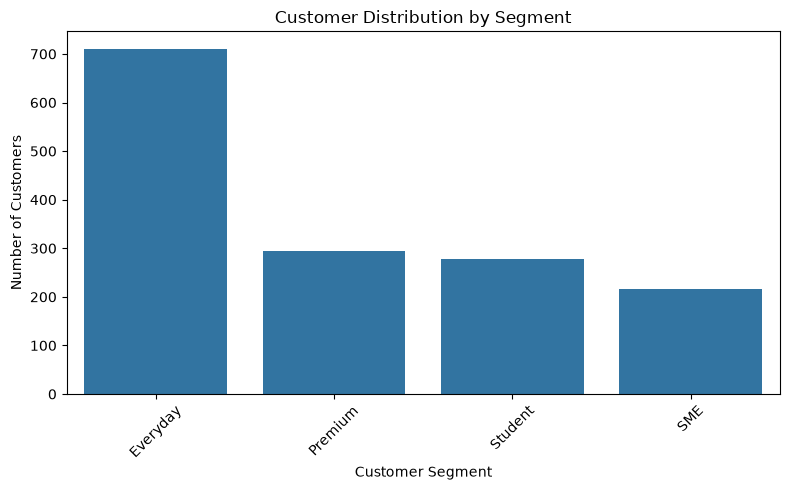

In [11]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=customers,
    x="customer_segment",
    order=customers["customer_segment"].value_counts().index
)

plt.title("Customer Distribution by Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [12]:
transactions["transaction_type"].value_counts()

transaction_type
Transfer           3549
Card Purchase      3033
Bill Payment       1475
Cash Withdrawal    1430
Deposit            1328
Airtime/Data       1185
Name: count, dtype: int64

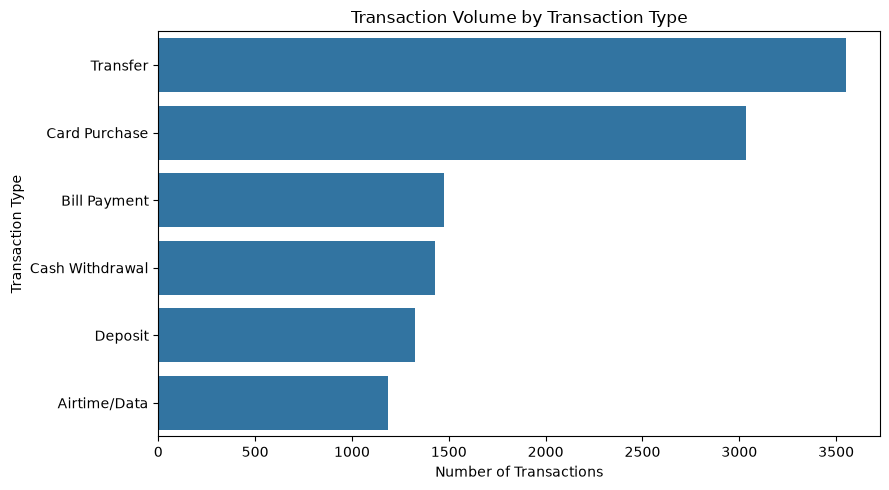

In [13]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=transactions,
    y="transaction_type",
    order=transactions["transaction_type"].value_counts().index
)

plt.title("Transaction Volume by Transaction Type")
plt.xlabel("Number of Transactions")
plt.ylabel("Transaction Type")
plt.tight_layout()
plt.show()

In [14]:
transactions["amount_NGN"].describe()

count     12000.000000
mean      46706.446238
std       86028.715234
min         100.170000
25%        2192.220000
50%       10305.935000
75%       48484.475000
max      693454.450000
Name: amount_NGN, dtype: float64

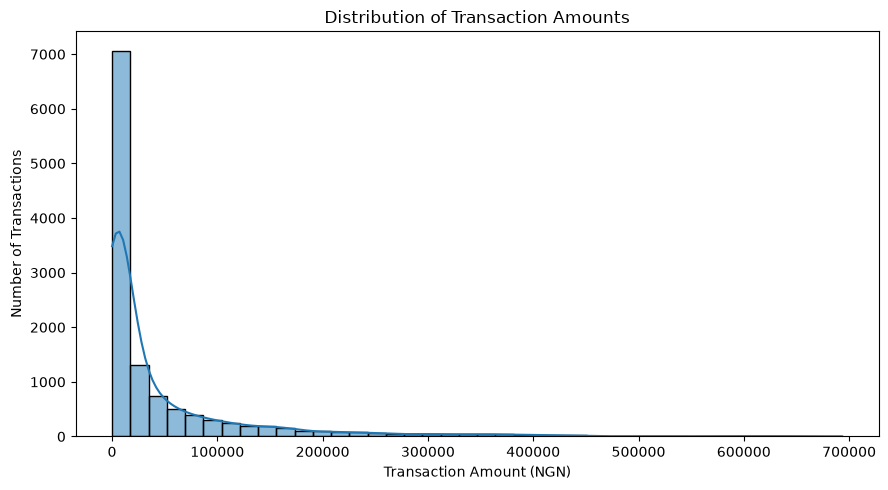

In [15]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=transactions,
    x="amount_NGN",
    bins=40,
    kde=True
)

plt.title("Distribution of Transaction Amounts")
plt.xlabel("Transaction Amount (NGN)")
plt.ylabel("Number of Transactions")
plt.tight_layout()
plt.show()

**Transaction Amount Analysis**

#The transaction amounts range from approximately ₦100 to ₦693,454, with an average transaction value of ₦46,706 and a median of ₦10,306. The substantial difference between the mean and median indicates that the transaction amount distribution is positively skewed, with a smaller number of high-value transactions increasing the average.

**Business Insight:**  
Most transactions are relatively lower in value, while a smaller number involve substantially higher amounts. FinTrust should therefore monitor transaction value patterns and consider segmenting transactions by value when analyzing customer behaviour and risk.

In [16]:
transactions["channel"].value_counts()

channel
Mobile App    5102
POS           2393
Web           1869
ATM           1747
USSD           889
Name: count, dtype: int64

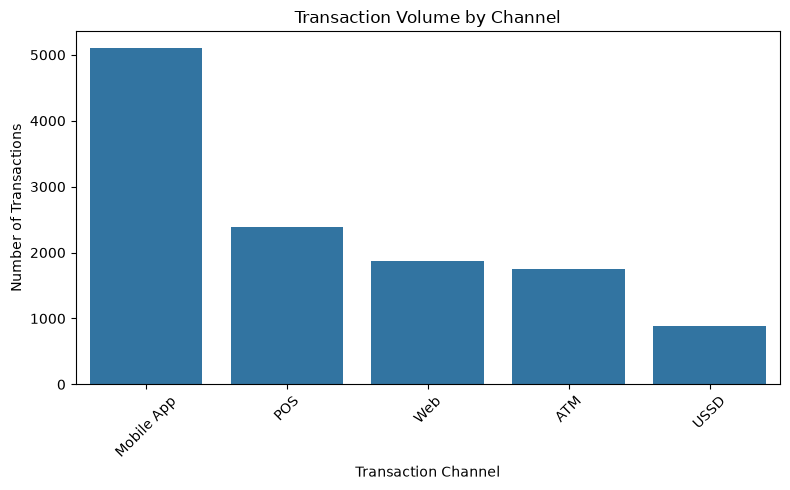

In [17]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=transactions,
    x="channel",
    order=transactions["channel"].value_counts().index
)

plt.title("Transaction Volume by Channel")
plt.xlabel("Transaction Channel")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Transaction Channel Analysis**

The Mobile App is the most frequently used transaction channel, accounting for 5,102 transactions (42.5%). POS follows with 2,393 transactions (19.9%), while Web, ATM, and USSD account for smaller proportions of transaction activity.

**Business Insight:**  
The strong usage of the Mobile App indicates that digital banking is an important part of customer transaction behaviour. FinTrust should continue to prioritize the reliability, usability, and security of its mobile banking experience while maintaining support for alternative channels.

In [18]:
transactions["transaction_status"].value_counts()

transaction_status
Successful    10856
Failed          630
Reversed        326
Pending         188
Name: count, dtype: int64

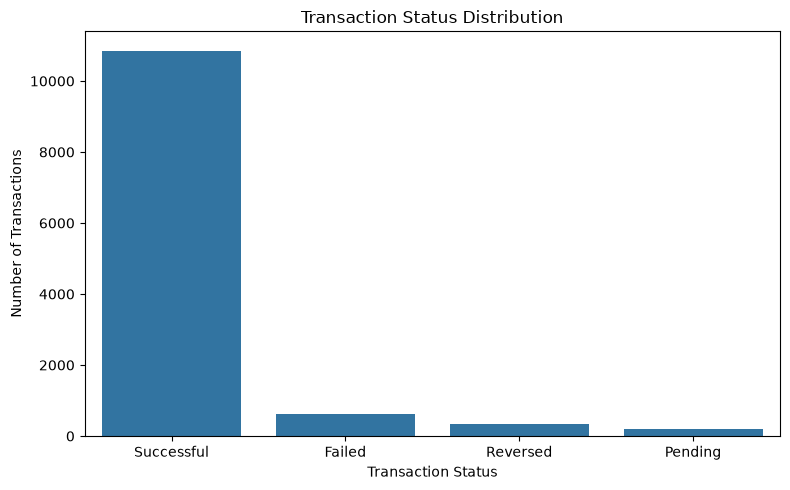

In [19]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=transactions,
    x="transaction_status",
    order=transactions["transaction_status"].value_counts().index
)

plt.title("Transaction Status Distribution")
plt.xlabel("Transaction Status")
plt.ylabel("Number of Transactions")
plt.tight_layout()
plt.show()

**Transaction Status Analysis**

The majority of FinTrust transactions were successful, with 10,856 transactions (90.5%) recorded as successful. Failed transactions accounted for 630 (5.3%), while reversed and pending transactions accounted for 326 (2.7%) and 188 (1.6%) respectively.

**Business Insight:**  
The high successful transaction rate indicates generally strong transaction completion. However, the 1,144 transactions that were failed, reversed, or pending represent opportunities to investigate transaction reliability and identify operational issues that may affect customer experience.

In [20]:
transactions["international_transaction"].value_counts()

international_transaction
No     11520
Yes      480
Name: count, dtype: int64

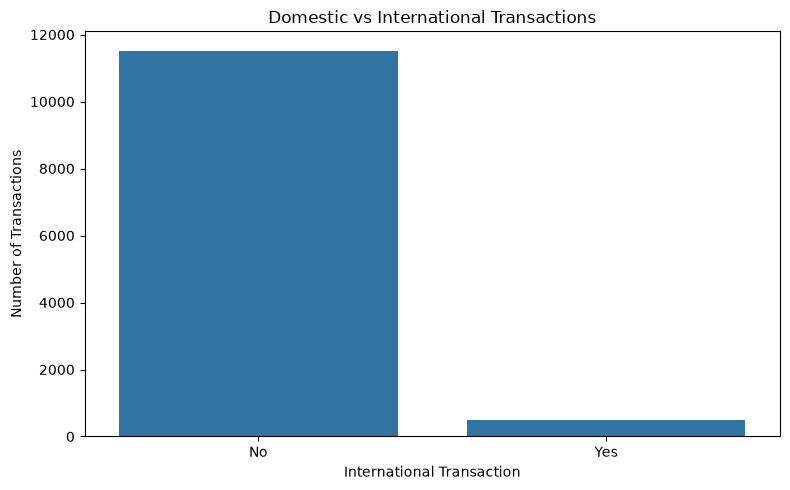

In [21]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=transactions,
    x="international_transaction"
)

plt.title("Domestic vs International Transactions")
plt.xlabel("International Transaction")
plt.ylabel("Number of Transactions")
plt.tight_layout()
plt.show()

## International Transaction Analysis

The dataset contains 12,000 transactions, of which 11,520 (96.0%) are domestic and 480 (4.0%) are international.

**Business Insight:** International transactions represent a relatively small proportion of overall transaction activity. However, because international transactions can involve different transaction characteristics and risk considerations, comparing their risk-review rates with domestic transactions provides additional insight into the bank's risk-monitoring patterns.

In [22]:
transactions["risk_review_flag"].value_counts()

risk_review_flag
No     9648
Yes    2352
Name: count, dtype: int64

In [23]:
risk_rate = pd.crosstab(
    transactions["international_transaction"],
    transactions["risk_review_flag"],
    normalize="index"
) * 100

print(risk_rate)

risk_review_flag                  No        Yes
international_transaction                      
No                         81.119792  18.880208
Yes                        63.125000  36.875000


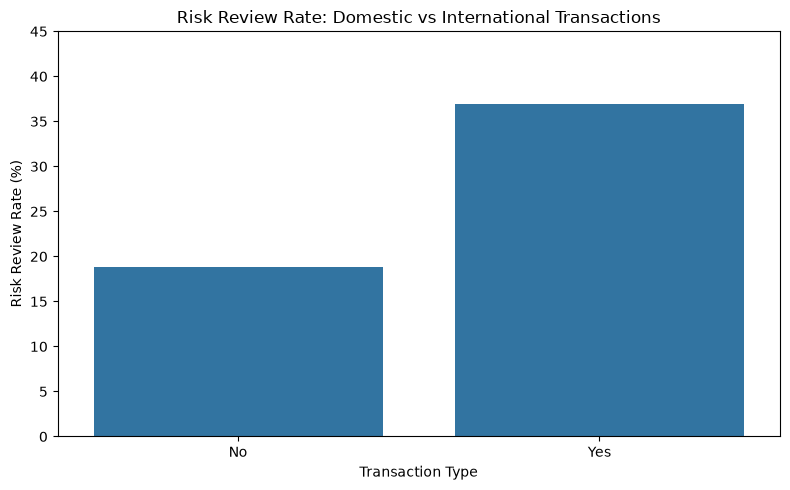

In [24]:
risk_review_plot = risk_rate["Yes"].reset_index()
risk_review_plot.columns = ["Transaction Type", "Risk Review Rate"]

plt.figure(figsize=(8, 5))

sns.barplot(
    data=risk_review_plot,
    x="Transaction Type",
    y="Risk Review Rate"
)

plt.title("Risk Review Rate: Domestic vs International Transactions")
plt.xlabel("Transaction Type")
plt.ylabel("Risk Review Rate (%)")
plt.ylim(0, 45)
plt.tight_layout()
plt.show()

**Risk Review Analysis**

Risk-review rates differ substantially between domestic and international transactions. International transactions had a risk-review rate of 36.9%, compared with 18.9% for domestic transactions. This means international transactions were flagged for review at approximately 1.95 times the rate of domestic transactions in the dataset.

**Business Insight:**  
The higher review rate associated with international transactions indicates that this transaction category warrants closer monitoring. FinTrust could investigate the characteristics of these transactions further to understand the factors associated with increased review activity. However, the analysis shows an association and does not establish that international transactions are inherently fraudulent or risky.

In [25]:
customer_transactions = transactions.merge(
    customers[["customer_id", "customer_segment"]],
    on="customer_id",
    how="left"
)

customer_transactions.head()

,transaction_id,customer_id,transaction_date,transaction_type,amount_NGN,channel,device_type,location,international_transaction,transaction_status,risk_review_flag,customer_segment
0,FT-T000001,FT-C01135,2026-01-01,Card Purchase,5923.80,Mobile App,Android,Enugu,No,Reversed,Yes,Everyday
1,FT-T000002,FT-C00428,2026-01-01,Cash Withdrawal,11681.12,ATM,Android,Kaduna,No,Successful,Yes,Everyday
2,FT-T000003,FT-C00469,2026-01-01,Transfer,571.91,ATM,POS Terminal,Kano,No,Successful,No,Everyday
3,FT-T000004,FT-C01015,2026-01-01,Deposit,105367.52,Mobile App,Web Browser,Abuja,No,Successful,No,Everyday
4,FT-T000005,FT-C00870,2026-01-01,Cash Withdrawal,3049.06,Mobile App,POS Terminal,Abuja,No,Successful,No,Everyday


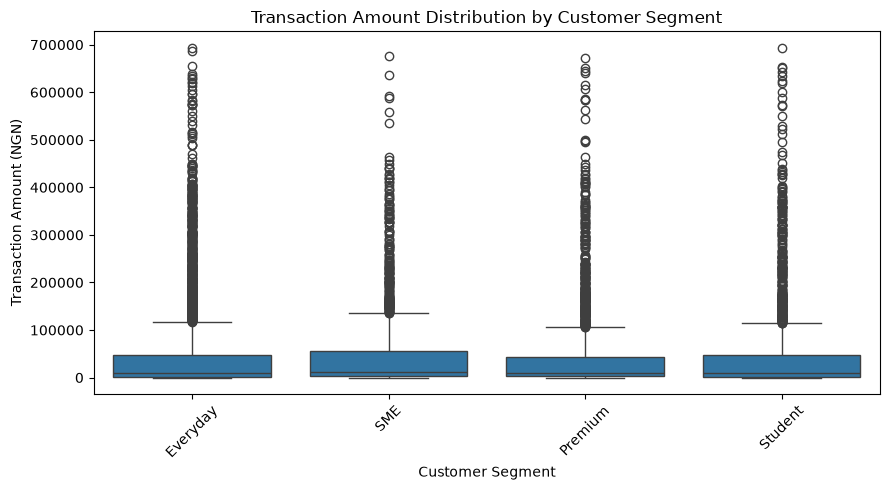

In [26]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=customer_transactions,
    x="customer_segment",
    y="amount_NGN"
)

plt.title("Transaction Amount Distribution by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Transaction Amount (NGN)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [27]:
customer_transactions.groupby("customer_segment")["amount_NGN"].agg(
    ["count", "mean", "median", "min", "max"]
).round(2)

,count,mean,median,min,max
customer_segment,,,,,
Everyday,5644,46325.11,9928.88,100.17,693454.45
Premium,2361,45637.95,10218.87,100.20,672369.02
SME,1706,49115.69,11626.76,101.36,675336.55
Student,2289,46953.20,10531.04,101.73,693006.62


## Customer Behaviour Analysis

Transaction behaviour was compared across customer segments using transaction amounts. SME customers recorded the highest average transaction amount at ₦49,115.69 and the highest median transaction amount at ₦11,626.76. Everyday customers recorded the lowest average transaction amount at ₦46,325.11.

**Business Insight:** The relatively higher transaction values among SME customers may indicate greater transaction-value activity within this segment. This could support further analysis of SME banking needs and transaction patterns. However, the differences between segments are relatively modest, so customer segment alone should not be treated as a strong predictor of transaction value.

In [28]:
risk_by_type = pd.crosstab(
    transactions["transaction_type"],
    transactions["risk_review_flag"],
    normalize="index"
) * 100

print(risk_by_type.round(2))

risk_review_flag     No    Yes
transaction_type              
Airtime/Data      84.81  15.19
Bill Payment      87.19  12.81
Card Purchase     86.98  13.02
Cash Withdrawal   74.69  25.31
Deposit           83.81  16.19
Transfer          71.51  28.49


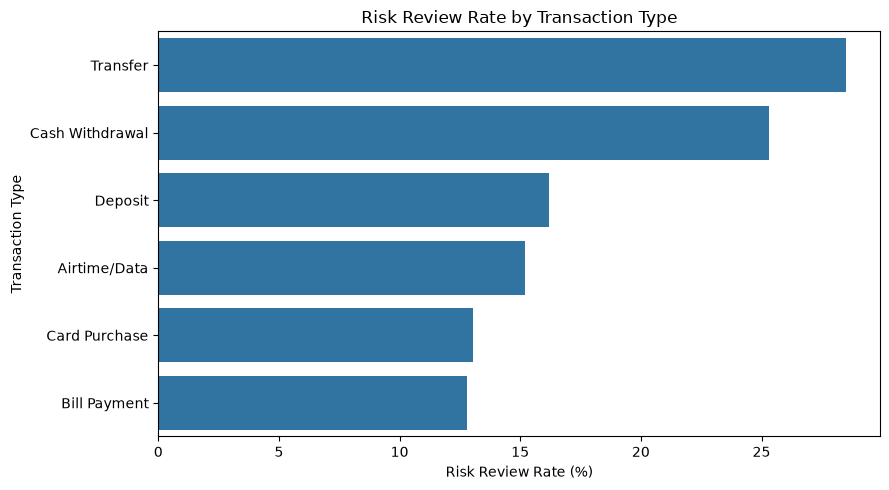

In [29]:
risk_type_plot = risk_by_type["Yes"].sort_values(ascending=False).reset_index()
risk_type_plot.columns = ["Transaction Type", "Risk Review Rate"]

plt.figure(figsize=(9, 5))

sns.barplot(
    data=risk_type_plot,
    x="Risk Review Rate",
    y="Transaction Type"
)

plt.title("Risk Review Rate by Transaction Type")
plt.xlabel("Risk Review Rate (%)")
plt.ylabel("Transaction Type")
plt.tight_layout()
plt.show()

**Risk Review by Transaction Type**

Risk-review rates vary considerably across transaction types. Transfers have the highest risk-review rate at 28.5%, followed by Cash Withdrawals at 25.3%. Deposits and Airtime/Data transactions have review rates of 16.2% and 15.2%, while Card Purchases and Bill Payments have the lowest rates at 13.0% and 12.8% respectively.

**Business Insight:**  
The higher review rates observed for Transfers and Cash Withdrawals indicate that these transaction types may warrant closer monitoring and further investigation into the characteristics associated with review flags. The analysis identifies patterns in review activity but does not establish that reviewed transactions are fraudulent.

# Business Recommendations

Based on the exploratory analysis, the following recommendations can support FinTrust's business and operational decision-making:

### 1. Strengthen Mobile Banking Services
The Mobile App accounts for the largest share of transaction activity. FinTrust should continue improving mobile-app reliability, usability, security, and customer support to maintain strong digital engagement.

### 2. Monitor High-Review Transaction Types
Transfers and Cash Withdrawals have the highest risk-review rates. FinTrust should investigate the characteristics of transactions that trigger reviews and assess whether additional monitoring or improved review processes are required.

### 3. Enhance Monitoring of International Transactions
International transactions have a substantially higher risk-review rate than domestic transactions. The bank should examine these transactions further to understand the characteristics associated with increased review activity and ensure appropriate monitoring controls are in place.

### 4. Improve Transaction Reliability
Although 90.5% of transactions were successful, failed, reversed, and pending transactions still represent a meaningful operational area for investigation. FinTrust should identify the common causes of unsuccessful transactions and use the findings to improve customer experience.

### 5. Develop Segment-Specific Banking Products
The customer base contains distinct Everyday, Premium, Student, and SME segments. FinTrust can use transaction behaviour and customer characteristics to develop products, services, and engagement strategies that better address the needs of each segment.

### 6. Further Analyze High-Value Transactions
Transaction amounts are highly skewed, with a relatively small number of high-value transactions contributing significantly to the overall average. Further analysis of high-value transactions could help FinTrust understand customer behaviour and support appropriate monitoring and service strategies.

# Conclusion

The exploratory analysis provides an overview of FinTrust Bank's customer and transaction behaviour across multiple dimensions. The findings show strong activity through digital channels, particularly the Mobile App, with Transfers representing the most common transaction type.

The analysis also identifies meaningful differences in risk-review activity. International transactions and certain transaction types, particularly Transfers and Cash Withdrawals, recorded higher review rates within the dataset. These patterns provide useful areas for further investigation rather than evidence of fraudulent activity.

Overall, the findings can support FinTrust's decisions around digital banking, customer segmentation, transaction reliability, and risk monitoring. Further analysis using additional customer, transaction, and risk-related variables could provide deeper insight into the factors driving these patterns.